# PydanticAI together with Pydantic Models

In [4]:
from model import nvidia_model
from pydantic_ai import Agent

employee_simulator = Agent(
    model=nvidia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige. Simulera i detta formatet likt exemplet"
    """
        name: "Bertil",
        age: "49",
        lön: 35000,
        role: "IT-Support,
        ort: "Göteborg"

    """
    )

result= await employee_simulator.run("Ge mig en data engineer som jobbar i stockholm")
print(result.output)

        name: "Sofia Karlsson",
        age: "34",
        lön: 59000,
        role: "Data Engineer",
        ort: "Stockholm"


## Force a structured output using pydantic

In [5]:
from pydantic import BaseModel, Field


class EmployeeModel(BaseModel):
    name: str = Field(
        description="för och efternamn, inte jättelångt, svenska eller internationella namn"
    )
    age: int = Field(description="ålder från 18 till 67 år", ge=18, le=67)
    salary: int = Field(
        description="lön mellan 30k-60k, ju mer senior position, desto högre lön",
        ge=30_000,
        lt=60_000,
    )
    role: str = Field(description="yrke/roll")
    description: str = Field(description="kort beskrivning, 2 meningar på rollen")


employee1 = EmployeeModel(
    name="Bertil",
    age=40,
    salary=30000,
    role="IT supporter",
    description="Hjälper folk med IT",
)

employee1

EmployeeModel(name='Bertil', age=40, salary=30000, role='IT supporter', description='Hjälper folk med IT')

In [6]:
employee_simulator = Agent(
    model=nvidia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige. Simulera i detta formatet likt exemplet")

result = await employee_simulator.run("Ge mig en data engineer i stockholm")
result.output

'**NAMN:** David Eriksson  \n**TITEL:** Data Engineer  \n**PLATS:** Stockholm, Sverige (hybrid, kontor i Södermalm)  \n**ANSTÄLLNING:** Tillsvidareanställning, heltid (100%), provanställning 6 månader avslutad  \n**BOLAG:** Medeltillväxtbolag inom fintech, ~200 anställda, kollektivavtal via Unionen/Almega Tjänsteföretagen  \n\n---\n\n### ERSÄTTNING & FÖRMÅNER\n- **Lön:** 58 000 SEK/månad (lönerevision årligen)  \n- **Semester:** 28 dagar/år  \n- **Tjänstepension:** ITP1 (4,5–30 % beroende på ålder, arbetsgivare betalar)  \n- **Förmåner:** Friskvårdsbidrag 3 000 SEK/år, tjänstedator (MacBook Pro), mobiltelefon, SL-kort/subventionerat kollektivtrafik, friskvårdstimme  \n- **Övrigt:** Tjänstecykel via löneväxling, möjlighet till remote arbete 2–3 dagar/vecka  \n\n---\n\n### BAKGRUND & UTBILDNING\n- **Utbildning:** Högskoleingenjör, Datateknik, KTH (2018)  \n- **Yrkeserfarenhet:** 6 år (varav 3 år som Data Engineer, tidigare konsult på ett större IT-konsultbolag i Stockholm)  \n- **Personn

In [7]:
result = await employee_simulator.run("Ge mig en data engineer i stockholm", output_type=EmployeeModel)
result

AgentRunResult(output=EmployeeModel(name='Erik Andersson', age=34, salary=52000, role='Data Engineer', description='Erik arbetar med att designa, bygga och underhålla datapipeliner och molnbaserade dataplattformar för ett techbolag i Stockholm. Han ser till att data är tillgänglig, tillförlitlig och optimerad för analys och maskininlärning.'))

In [8]:
employee2 = result.output
employee2

EmployeeModel(name='Erik Andersson', age=34, salary=52000, role='Data Engineer', description='Erik arbetar med att designa, bygga och underhålla datapipeliner och molnbaserade dataplattformar för ett techbolag i Stockholm. Han ser till att data är tillgänglig, tillförlitlig och optimerad för analys och maskininlärning.')

In [9]:
type(employee2)

__main__.EmployeeModel

In [10]:
employee2.name + " är cool"

'Erik Andersson är cool'

In [11]:
employee2.salary

52000

In [12]:
employee2.__dict__.keys()

dict_keys(['name', 'age', 'salary', 'role', 'description'])

In [13]:
employee2.__dict__.values()

dict_values(['Erik Andersson', 34, 52000, 'Data Engineer', 'Erik arbetar med att designa, bygga och underhålla datapipeliner och molnbaserade dataplattformar för ett techbolag i Stockholm. Han ser till att data är tillgänglig, tillförlitlig och optimerad för analys och maskininlärning.'])

In [14]:
for key, value in employee2.__dict__.items():
    print(f"{key}: {value}")

name: Erik Andersson
age: 34
salary: 52000
role: Data Engineer
description: Erik arbetar med att designa, bygga och underhålla datapipeliner och molnbaserade dataplattformar för ett techbolag i Stockholm. Han ser till att data är tillgänglig, tillförlitlig och optimerad för analys och maskininlärning.


## Simulate many employees

In [15]:
result = await employee_simulator.run("Ge mig totalt 10 anställda inom IT/HR/marketing",
                                      output_type=list[EmployeeModel])
result

AgentRunResult(output=[EmployeeModel(name='Anna Svensson', age=34, salary=42000, role='Systemutvecklare', description='Utvecklar och underhåller webbapplikationer för företagets kunder. Arbetar i ett agilt team med fokus på kodkvalitet och leverans.'), EmployeeModel(name='Erik Johansson', age=29, salary=38000, role='IT-support', description='Hjälper kollegor med datorproblem, programvara och nätverksanslutningar. Ansvarar även för att dokumentera vanliga fel och lösningar.'), EmployeeModel(name='Maria Gomez', age=41, salary=52000, role='Säkerhetsanalytiker', description='Övervakar företagets IT-säkerhet och utreder potentiella intrång. Implementerar skyddsåtgärder och utbildar personal i säkerhetsmedvetenhet.'), EmployeeModel(name='Lars Nilsson', age=55, salary=57000, role='UX-designer', description='Skapar användarvänliga gränssnitt för digitala produkter och tjänster. Genomför användartester och omarbetar design utifrån feedback.'), EmployeeModel(name='Sofia Karlsson', age=26, salary

## Task - calculate mean salary

In [16]:
employees = result.output

employees

[EmployeeModel(name='Anna Svensson', age=34, salary=42000, role='Systemutvecklare', description='Utvecklar och underhåller webbapplikationer för företagets kunder. Arbetar i ett agilt team med fokus på kodkvalitet och leverans.'),
 EmployeeModel(name='Erik Johansson', age=29, salary=38000, role='IT-support', description='Hjälper kollegor med datorproblem, programvara och nätverksanslutningar. Ansvarar även för att dokumentera vanliga fel och lösningar.'),
 EmployeeModel(name='Maria Gomez', age=41, salary=52000, role='Säkerhetsanalytiker', description='Övervakar företagets IT-säkerhet och utreder potentiella intrång. Implementerar skyddsåtgärder och utbildar personal i säkerhetsmedvetenhet.'),
 EmployeeModel(name='Lars Nilsson', age=55, salary=57000, role='UX-designer', description='Skapar användarvänliga gränssnitt för digitala produkter och tjänster. Genomför användartester och omarbetar design utifrån feedback.'),
 EmployeeModel(name='Sofia Karlsson', age=26, salary=35000, role='Data

In [17]:
salary = 0

for employee in employees:
    salary += employee.salary

salary/len(employees)

44600.0

## Convert to dataframe

In [18]:
employees[0].model_dump()

{'name': 'Anna Svensson',
 'age': 34,
 'salary': 42000,
 'role': 'Systemutvecklare',
 'description': 'Utvecklar och underhåller webbapplikationer för företagets kunder. Arbetar i ett agilt team med fokus på kodkvalitet och leverans.'}

In [19]:
import pandas as pd
df = pd.DataFrame([employee.model_dump() for employee in employees])
df.head()

,name,age,salary,role,description
0,Anna Svensson,34,42000,Systemutvecklare,Utvecklar och underhåller webbapplikationer fö...
1,Erik Johansson,29,38000,IT-support,"Hjälper kollegor med datorproblem, programvara..."
2,Maria Gomez,41,52000,Säkerhetsanalytiker,Övervakar företagets IT-säkerhet och utreder p...
3,Lars Nilsson,55,57000,UX-designer,Skapar användarvänliga gränssnitt för digitala...
4,Sofia Karlsson,26,35000,Dataanalytiker,Samlar in och analyserar affärsdata för att st...


In [20]:
df.to_csv("employees.csv", index=None)

<Axes: ylabel='name'>

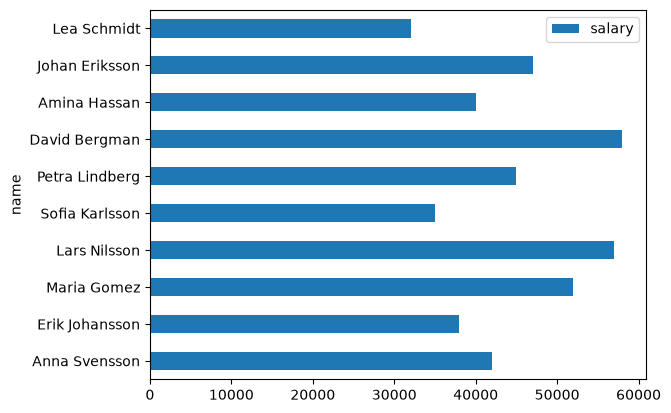

In [21]:
df.plot(kind = "barh", x = "name", y = "salary")